# 1. When does main proficiency outweigh a stronger alternative matchup?

Compare the same player, opponent, lane and target time, keeping only validation alternatives whose **raw Global Master+ matchup probability is strictly greater than the main's**. Main remains the existing all-role pregame main. Both choices require at least one prior same-role game; all-role count and historical WR remain the fitted proficiency features.

A is ordinary usage-based Combined LR; B is nonlinear player-intercept HLR; C adds strongly pooled player–champion deviations. All remain visible. B/C variational intervals are model-conditional, not recommendations. An independently implemented training-only Pyro NUTS check assesses B on a reproducible subset; C remains approximate. No test outcomes are accessed, and no model is chosen for a preferred specialization story.

In [1]:
from pathlib import Path
import sys,json,time,hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from IPython.display import display,Markdown
import torch,scipy,sklearn
%matplotlib inline
start=Path.cwd().resolve()
ROOT=next((p for p in [start,*start.parents] if (p/'hlr_model/tradeoff_helpers.py').is_file()),None)
if ROOT is None:raise FileNotFoundError('Run from repository root or hlr_model/.')
sys.path.insert(0,str(ROOT/'hlr_model'))
from tradeoff_helpers import (Design,NonlinearVI,observed_frame,candidate_frame,keys_pc,metrics,
    preference_labels,weighted_pair_mean,preference_summary,point_agreement_summary,
    select_supported_examples,mcmc_parameter_draws,rank_mcmc_diagnostics,pyro_player_model,run_player_mcmc)
DATA=ROOT/'hlr_model/data/final/20261020T180254240509Z'
KEY=['puuid','match_id']
G='global_raw_matchup_winrate_probability'
dictionary=pd.read_csv(DATA/'data_dictionary.csv')
readme=(DATA/'README.md').read_text()
# Fingerprint protected notebooks and input parquet files: final check is read-only.
protected=[ROOT/'hlr_model'/n for n in ['hlr_EDAfinal.ipynb','hlr_modeling.ipynb']]+list(DATA.glob('*.parquet'))
def digest(p):return hashlib.sha256(p.read_bytes()).hexdigest()
source_hashes={p:digest(p) for p in protected}
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
def note(s):display(Markdown(s))
def table(x):
    formats={c:'{:.5f}' for c in ['log_loss','Brier','AUC','equal_player_log_loss','equal_player_Brier'] if c in x.columns}
    formats.update({c:'{:.2e}' for c in ['max_gradient','ELBO_per_row_change','max_fixed_mean_change','log_k_mean_change'] if c in x.columns})
    for col in x.columns:
        if col in ['pair_weighted','equal_target','equal_player','pair_retention','target_retention','player_retention'] or (isinstance(col,tuple) and col[0] in ['pair_weighted','equal_target','equal_player']):
            formats[col]='{:.1%}'
    display(x.style.format(formats,precision=3,na_rep='—'))
def done():plt.tight_layout();plt.show();plt.close('all')
print('Versions: torch',torch.__version__,'scipy',scipy.__version__,'sklearn',sklearn.__version__)

Versions: torch 2.13.0 scipy 1.13.1 sklearn 1.5.1


## 2. Fixed data, histories and chronology

Histories expand from **up to 170 initial season-bounded games plus earlier targets completed strictly before kickoff**; they are not a rolling last-170 window. The selected champion's all-role count, raw WR and Beta(1,1) WR differ from same-role support. At zero recorded history, Beta WR = 0.5 is a prior assumption, not known skill or an imputed matchup.

Preserve validation kickoff October 2, 2026 22:25:06.238 UTC and test kickoff October 5 01:32:18.312 UTC. Whole shared matches remain together; purge games unfinished at each fitting cutoff. Only observed training outcomes fit parameters/scaling. Candidate outcomes are never duplicated, and held-out results never update player effects. Lane/opponent are postgame-inferred, so prospective use needs a defensible pregame mapping. Global remains primary, with no substitution or benchmark filling.

In [2]:
obs_cols=KEY+['timestamp','end_timestamp','champion_id','champion','lane','opponent_champion_id',
 'prior_total_games','prior_champion_games','prior_champion_wr_beta11','prior_champion_usage_share',G]
base=pd.read_parquet(DATA/'observed_global_analysis.parquet',columns=obs_cols)
assert len(base)==7227 and not base.duplicated(KEY).any()
cut1=pd.Timestamp('2026-10-02 22:25:06.238',tz='UTC').value//10**6
cut2=pd.Timestamp('2026-10-05 01:32:18.312',tz='UTC').value//10**6
base['partition']=np.select([base.timestamp.lt(cut1),base.timestamp.lt(cut2)],['train','validation'],default='test')
assert base.groupby('match_id').partition.nunique().eq(1).all()
pending1=base.loc[base.timestamp.lt(cut1)&base.end_timestamp.ge(cut1),'match_id'].unique()
pending2=base.loc[base.timestamp.lt(cut2)&base.end_timestamp.ge(cut2),'match_id'].unique()
labels=pd.read_parquet(DATA/'observed_global_analysis.parquet',columns=KEY+['win'],filters=[('timestamp','<',int(cut2))])
train=observed_frame(base.loc[base.partition.eq('train')&~base.match_id.isin(pending1)].merge(labels,on=KEY,validate='one_to_one'))
val=observed_frame(base.loc[base.partition.eq('validation')&~base.match_id.isin(pending2)].merge(labels,on=KEY,validate='one_to_one'))
candidate_cols=KEY+['timestamp','candidate_champion_id','candidate_champion','observed_champion_id',
 'opponent_champion_id','opponent_champion','lane','is_observed_pick','is_eligible_alternative',
 'is_existing_pregame_main','is_pregame_same_role_main','prior_total_games',
 'all_role_prior_games','all_role_prior_wr','all_role_prior_wr_beta11','all_role_prior_usage_share',
 'same_role_prior_games','global_valid_rate',G,'global_raw_matchup_winrate_pct',
 'global_matchup_games','global_verified_lane','global_verified_region']
candidates=pd.read_parquet(DATA/'candidate_champion_comparisons.parquet',columns=candidate_cols)
candidates=candidates.merge(pd.concat([train[KEY],val[KEY]]),on=KEY,how='inner',validate='many_to_one')
assert 'win' not in candidates and 'observed_pick_win' not in candidates
actual=candidate_frame(candidates.loc[candidates.is_observed_pick]).set_index(KEY).sort_index()
tv=pd.concat([train,val]).set_index(KEY).sort_index()
assert actual.index.equals(tv.index)
for col in ['champion_id','n','wr','usage','matchup','log_total','timestamp','opponent_champion_id']:
 assert np.allclose(actual[col],tv[col],equal_nan=True),col
assert actual.lane.equals(tv.lane)
assert candidates.loc[candidates.global_valid_rate,G].between(0,1).all()
assert np.allclose(candidates.loc[candidates.global_valid_rate,G]*100,
                   candidates.loc[candidates.global_valid_rate,'global_raw_matchup_winrate_pct'])
display(dictionary.loc[dictionary.dataset.eq('candidate_champion_comparisons')&dictionary.field.isin([
 'all_role_prior_games','all_role_prior_wr_beta11','all_role_prior_usage_share','same_role_prior_games',
 'is_eligible_alternative',G]),['field','units','definition']])
print('Actual-pick mapping: all',len(tv),'training/validation targets reproduce observed features.')

,field,units,definition
281,is_eligible_alternative,boolean,Unplayed saved candidate with strictly prior s...
289,all_role_prior_games,count,Count from preserved initial history plus earl...
292,all_role_prior_wr_beta11,probability 0–1,"Beta(1,1) posterior mean (prior wins+1)/(prior..."
293,all_role_prior_usage_share,proportion 0–1,Prior candidate games in named scope divided b...
294,same_role_prior_games,count,Count from preserved initial history plus earl...
361,global_raw_matchup_winrate_probability,probability 0–1,GLOBAL retrospective Master+ patch-16.19: Vali...


Actual-pick mapping: all 6135 training/validation targets reproduce observed features.


## 3. Restore the fixed models and validate actual picks

Filtering candidate comparisons does not change observed training rows or model specifications. The prior notebook did not serialize fits, so the original training-only VI fits must be reproduced once, then may be reused from a fingerprinted temporary cache. A reproduces the existing ordinary Combined LR (`C=1`). B/C preserve `β_exp n/(n+k)`, the original priors, training scaling and noncentered effects. There is no threshold-dependent refitting.

B/C priors: fixed coefficients Normal(0,2²); experience amplitude Normal(0,1); log k Normal(log 30,1²); log player SD Normal(log 0.3,0.7²); standardized group latents Normal(0,1). C adds log player–champion SD Normal(log 0.15,0.5²). Historical wins are features, not extra likelihood observations. The helper's Gaussian KL, conditional-normal expectation, and transformed prediction draws correspond to that generative model. Optimizer stability is only numerical evidence; Section 6 independently checks the posterior approximation.

A uses usage share while B/C use saturating champion counts, so A–B contrasts change predictor specification as well as hierarchy. None isolates the effect of partial pooling alone.

In [3]:
import inspect,pickle
fit_fingerprint=hashlib.sha256((inspect.getsource(NonlinearVI)+inspect.getsource(Design)+
    digest(DATA/'observed_global_analysis.parquet')+'unchanged training cutoff '+str(cut1)).encode()).hexdigest()
fit_cache=Path('/tmp/tradeoff_fixed_training_fits.pkl')
cache=None
if fit_cache.is_file():
    with fit_cache.open('rb') as handle: cached=pickle.load(handle)
    if cached.get('fingerprint')==fit_fingerprint:cache=cached
if cache is not None:
    reference_design,reference,B,C,fit_audit=cache['objects']
    print('Restored identical training-fitted models from fingerprinted temporary cache.')
    table(fit_audit)
else:
    print('No reusable serialized fits; reproduce the existing training specification once.')
    reference_design=Design(train,usage=True)
    reference=LogisticRegression(C=1.,solver='lbfgs',max_iter=1000,tol=1e-8).fit(reference_design.matrix(train)[:,1:],train.win)
    B=NonlinearVI(train).fit();C=NonlinearVI(train,rich=True).fit()
    audits=[]
    for label,model in [('B',B),('C',C)]:
        assert model.result.success
        refined=NonlinearVI(train,rich=model.rich).fit(start=model.result.x,power=8,seed=2026)
        assert refined.result.success and np.abs(refined.result.jac).max()<.01
        assert np.abs(refined.mu[:model.p+1]-model.mu[:model.p+1]).max()<.05
        audits.extend([model.diagnostics(label+' original'),refined.diagnostics(label+' refined')])
        if label=='B':B=refined
        else:C=refined
    fit_audit=pd.DataFrame(audits);table(fit_audit)
    with fit_cache.open('wb') as handle:
        pickle.dump({'fingerprint':fit_fingerprint,'objects':(reference_design,reference,B,C,fit_audit)},handle)
vc=candidates.merge(val[KEY],on=KEY,how='inner',validate='many_to_one')
supported=vc.loc[vc.same_role_prior_games.ge(1)&vc.global_valid_rate&vc[G].notna()].copy()
models={'B nonlinear player':B,'C nonlinear player–champion':C}
draws={name:model.draws(1200,2310) for name,model in models.items()}
validation_predictions={'A ordinary Combined':reference.predict_proba(reference_design.matrix(val)[:,1:])[:,1]}
for name,model in models.items():
    validation_predictions[name]=model.predict_draws(val,draws[name]).mean(axis=0)
scores=metrics(val,validation_predictions);table(scores)
support=[]
train_pcs=set(keys_pc(train))
for label,f in [('validation observed',val),('validation supported candidates',candidate_frame(supported))]:
    support.append({'scope':label,'rows':len(f),'unseen_player_rows':int((~f.puuid.isin(B.players)).sum()),
        'unseen_player_champion_rows':sum(k not in train_pcs for k in keys_pc(f))})
display(pd.DataFrame(support))

actual_val=candidate_frame(candidates.loc[candidates.is_observed_pick].merge(val[KEY],on=KEY,validate='one_to_one')).set_index(KEY).loc[pd.MultiIndex.from_frame(val[KEY])].reset_index()
np.testing.assert_allclose(reference.predict_proba(reference_design.matrix(actual_val)[:,1:])[:,1],validation_predictions['A ordinary Combined'],atol=1e-12)
for name,model in models.items():
    np.testing.assert_allclose(model.predict_draws(actual_val,draws[name]).mean(axis=0),validation_predictions[name],atol=1e-12)
print('A/B/C actual-pick prediction mappings passed before scoring alternatives.')

Restored identical training-fitted models from fingerprinted temporary cache.


,model,seconds,success,iterations,negative_ELBO,max_gradient,message
0,B original,23.825,True,118,3495.289,1.38e-03,CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
1,B refined,24.662,True,30,3495.329,6.21e-04,CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
2,C original,35.865,True,174,3497.212,3.38e-03,CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
3,C refined,26.450,True,34,3497.232,2.23e-04,CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH


,n,log_loss,Brier,AUC,equal_player_log_loss,equal_player_Brier
model,,,,,,
A ordinary Combined,1049,0.68344,0.24565,0.56118,0.68737,0.24760
B nonlinear player,1049,0.68550,0.24663,0.55412,0.68892,0.24834
C nonlinear player–champion,1049,0.68540,0.24659,0.55478,0.68887,0.24832


,scope,rows,unseen_player_rows,unseen_player_champion_rows
0,validation observed,1049,28,225
1,validation supported candidates,12911,331,6989


A/B/C actual-pick prediction mappings passed before scoring alternatives.


## 4. Strictly better-matchup alternatives and experience support

A comparable main must be saved, have prior same-role play and a valid Global estimate. Alternatives must have the same player, time, role, opponent and region and be distinct from that main. Actual off-main picks may qualify if historically supported; no actual result is assigned to another choice.

**Only comparison outputs are filtered** to alternative Global probability > main Global probability. Support sensitivities hold parameters fixed and require alternative same-role counts ≥1,5,10,20; a separate subset requires **both** counts ≥20. These are different supported populations, not threshold tuning. An eligibility count is not a proficiency score: fitted counts/WR are all-role measures.

In [4]:
scoring=candidate_frame(supported).reset_index(drop=True);scoring['candidate_row']=np.arange(len(scoring))
main_rows=scoring.loc[scoring.is_existing_pregame_main,KEY+['candidate_row']].rename(columns={'candidate_row':'main_row'})
alt_rows=scoring.loc[~scoring.is_existing_pregame_main&(scoring.is_eligible_alternative|scoring.is_observed_pick),KEY+['candidate_row']].rename(columns={'candidate_row':'alternative_row'})
unfiltered_pairs=alt_rows.merge(main_rows,on=KEY,validate='many_to_one')
keep=scoring.iloc[unfiltered_pairs.alternative_row].matchup.to_numpy()>scoring.iloc[unfiltered_pairs.main_row].matchup.to_numpy()
pairs=unfiltered_pairs.loc[keep].reset_index(drop=True)
ma=pairs.main_row.to_numpy();al=pairs.alternative_row.to_numpy()
for col in ['puuid','match_id','timestamp','lane','opponent_champion_id','global_verified_region']:
    assert np.array_equal(scoring.iloc[ma][col].to_numpy(),scoring.iloc[al][col].to_numpy()),col
candidate_point_A=reference.predict_proba(reference_design.matrix(scoring)[:,1:])[:,1]
pairs['A_main_p']=candidate_point_A[ma];pairs['A_alternative_p']=candidate_point_A[al]
pairs['A_difference_pp']=100*(candidate_point_A[al]-candidate_point_A[ma])
candidate_draws={};pair_draws={}
for name,model in models.items():
    probabilities=model.predict_draws(scoring,draws[name]);candidate_draws[name]=probabilities
    delta=100*(probabilities[:,al]-probabilities[:,ma]);pair_draws[name]=delta
    prefix='B' if model is B else 'C'
    pairs[prefix+'_main_p']=probabilities[:,ma].mean(axis=0)
    pairs[prefix+'_alternative_p']=probabilities[:,al].mean(axis=0)
    pairs[prefix+'_difference_pp']=delta.mean(axis=0)
    pairs[prefix+'_low_pp']=np.quantile(delta,.025,axis=0)
    pairs[prefix+'_high_pp']=np.quantile(delta,.975,axis=0)
    pairs[prefix+'_Pr_alternative_higher']=(delta>0).mean(axis=0)
player_labels={p:f'Player {i+1:03d}' for i,p in enumerate(sorted(base.puuid.unique()))}
counts=train.groupby(['puuid','champion_id']).size()
for suffix,indices in [('main',ma),('alternative',al)]:
    part=scoring.iloc[indices]
    for col in ['candidate_champion','n','wr','usage','all_role_prior_wr','same_role_prior_games','matchup','global_matchup_games','is_observed_pick']:
        pairs[suffix+'_'+col]=part[col].to_numpy()
    pairs[suffix+'_fitting_games']=[int(counts.get(k,0)) for k in keys_pc(part)]
    pairs[suffix+'_pc_seen']=pairs[suffix+'_fitting_games'].gt(0)
    pairs[suffix+'_low_matchup_n']=pairs[suffix+'_global_matchup_games'].lt(30)
    pairs[suffix+'_extrapolation']=(~part.n.between(train.n.min(),train.n.max())|~part.matchup.between(train.matchup.min(),train.matchup.max())).to_numpy()
pairs['player']=pairs.puuid.map(player_labels)
pairs['opponent']=scoring.iloc[al].opponent_champion.to_numpy();pairs['lane']=scoring.iloc[al].lane.to_numpy()
pairs['signal_pattern']=np.select([
    pairs.main_n.gt(pairs.alternative_n)&pairs.main_wr.gt(pairs.alternative_wr),
    pairs.main_n.gt(pairs.alternative_n)&pairs.main_wr.le(pairs.alternative_wr)],
    ['Main more games AND higher WR','Main more games; equal/lower WR'],default='Other or tied proficiency')
assert pairs.alternative_matchup.gt(pairs.main_matchup).all()
coverage=[];previous=set(map(tuple,val[KEY].to_numpy()))
for label,f,npairs in [('Validation targets',val,np.nan),
    ('Comparable main and alternative',unfiltered_pairs,len(unfiltered_pairs)),
    ('At least one strictly better-matchup alternative',pairs,len(pairs))]:
    keys=set(map(tuple,f[KEY].drop_duplicates().to_numpy()))
    coverage.append({'stage':label,'targets':len(keys),'players':f.puuid.nunique(),'candidate_pairs':npairs,
        'targets_excluded_this_stage':len(previous-keys)})
    previous=keys
display(pd.DataFrame(coverage))
scopes={f'Alternative ≥{n}':pairs.loc[pairs.alternative_same_role_prior_games.ge(n)].copy() for n in [1,5,10,20]}
scopes['Both ≥20']=pairs.loc[pairs.alternative_same_role_prior_games.ge(20)&pairs.main_same_role_prior_games.ge(20)].copy()
retention=[]
for label,f in scopes.items():
    retention.append({'scope':label,'pairs':len(f),'targets':len(f[KEY].drop_duplicates()),'players':f.puuid.nunique(),
      'pair_retention':len(f)/len(pairs),'target_retention':len(f[KEY].drop_duplicates())/len(pairs[KEY].drop_duplicates()),
      'player_retention':f.puuid.nunique()/pairs.puuid.nunique()})
table(pd.DataFrame(retention))
print('All counts use actual same-role support. Training rows and parameters are identical across scopes.')

,stage,targets,players,candidate_pairs,targets_excluded_this_stage
0,Validation targets,1049,128,NaN,0
1,Comparable main and alternative,834,119,10567.0,215
2,At least one strictly better-matchup alternative,712,117,4840.0,122


,scope,pairs,targets,players,pair_retention,target_retention,player_retention
0,Alternative ≥1,4840,712,117,100.0%,100.0%,100.0%
1,Alternative ≥5,1635,485,94,33.8%,68.1%,80.3%
2,Alternative ≥10,852,384,79,17.6%,53.9%,67.5%
3,Alternative ≥20,280,215,45,5.8%,30.2%,38.5%
4,Both ≥20,276,211,44,5.7%,29.6%,37.6%


All counts use actual same-role support. Training rows and parameters are identical across scopes.


## 5. Opposing signals, preferences and model agreement

“Main more games AND higher WR” most closely matches the motivating tradeoff. Main more games with equal/lower WR is a separate pattern; other/tied patterns are not relabeled as a single proficiency score.

For B/C: Main means the entire 95% alternative-minus-main interval is below zero, Alternative means entirely above zero, and Uncertain includes zero. A has **point directions only**, with no invented Bayesian interval. Point-direction agreement is distinct from interval classification.

All summaries include pair weighting, equal targets, and equal players. Equal-player results average within target first, then within player, then across players. Repeated main predictions, players and shared matches prohibit independent-pair significance tests. No recommended-choice “win rate” is calculated.

,scope,comparison,pair_weighted,equal_target,equal_player
0,Alternative ≥1,All three agree,62.1%,65.0%,67.3%
1,Alternative ≥1,A vs B disagree,36.9%,34.1%,32.1%
2,Alternative ≥1,A vs C disagree,36.9%,33.9%,32.2%
3,Alternative ≥1,B vs C disagree,2.0%,1.9%,1.2%
4,Alternative ≥5,All three agree,79.3%,78.7%,81.6%
5,Alternative ≥5,A vs B disagree,18.6%,19.1%,16.8%
6,Alternative ≥5,A vs C disagree,19.4%,19.9%,17.6%
7,Alternative ≥5,B vs C disagree,3.4%,3.5%,2.5%
8,Alternative ≥10,All three agree,88.1%,87.5%,86.6%
9,Alternative ≥10,A vs B disagree,9.6%,9.9%,11.1%


,pattern,pairs,targets,players,median_main_all_role_games,median_alt_all_role_games,median_main_same_role_games,median_alt_same_role_games,median_main_WR_beta,median_alt_WR_beta
0,Main more games AND higher WR,2884,648,113,42.000,2.000,39.000,2.000,0.551,0.333
1,Main more games; equal/lower WR,1955,526,98,41.000,4.000,37.000,3.000,0.528,0.667
2,Other or tied proficiency,1,1,1,30.000,30.000,30.000,29.000,0.594,0.500


,scope,event,pair_weighted,equal_target,equal_player
0,Alternative ≥1,B decisive AND C same preference,14.5%,16.2%,16.7%
1,Alternative ≥1,B decisive BUT C uncertain,47.1%,49.7%,50.1%
2,Alternative ≥1,B decisive BUT C opposite,0.0%,0.0%,0.0%
3,Alternative ≥5,B decisive AND C same preference,13.7%,12.3%,15.4%
4,Alternative ≥5,B decisive BUT C uncertain,44.9%,47.3%,47.8%
5,Alternative ≥5,B decisive BUT C opposite,0.0%,0.0%,0.0%
6,Alternative ≥10,B decisive AND C same preference,16.0%,14.3%,18.2%
7,Alternative ≥10,B decisive BUT C uncertain,46.8%,49.2%,48.9%
8,Alternative ≥10,B decisive BUT C opposite,0.0%,0.0%,0.0%
9,Alternative ≥20,B decisive AND C same preference,21.8%,20.0%,16.4%


,pc_training_support,pairs,targets,B_uncertain,C_uncertain
0,Both seen,2042,509,0.399,0.868
1,Neither seen,250,40,0.336,0.816
2,Only alternative seen,35,15,0.286,0.600
3,Only main seen,2513,610,0.378,0.852


,choice,median_matchup_n,share_n_below_10,share_n_below_30,share_n_below_50,extrapolation_share
0,main,504.000,0.020,0.069,0.115,0.004
1,alternative,337.000,0.031,0.082,0.127,0.000


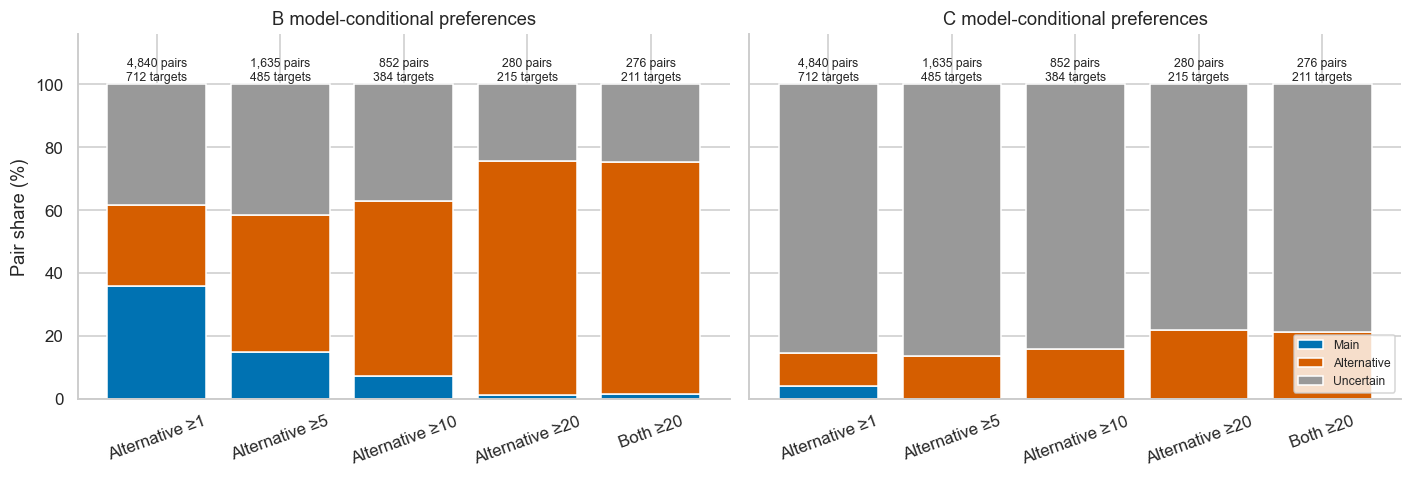

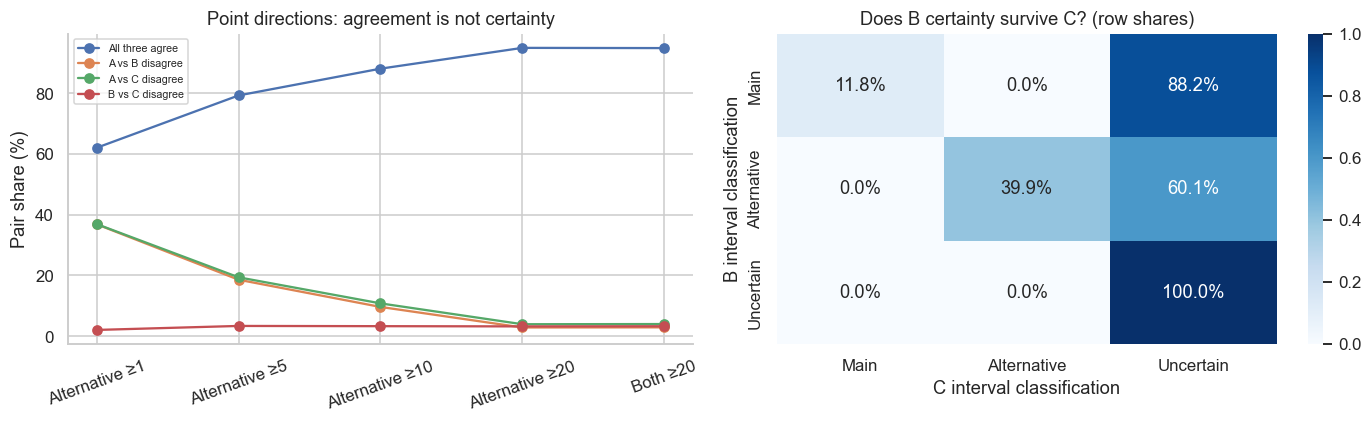

In [5]:
preference_tables=pd.concat([preference_summary(f,label) for label,f in scopes.items() if len(f)],ignore_index=True)
agreement_tables=pd.concat([point_agreement_summary(f,label) for label,f in scopes.items() if len(f)],ignore_index=True)
table(preference_tables.pivot(index=['scope','model'],columns='preference',values=['pair_weighted','equal_target','equal_player']))
table(agreement_tables)
signal_rows=[];signal_preferences=[]
for label in ['Main more games AND higher WR','Main more games; equal/lower WR','Other or tied proficiency']:
    f=pairs.loc[pairs.signal_pattern.eq(label)]
    signal_rows.append({'pattern':label,'pairs':len(f),'targets':len(f[KEY].drop_duplicates()),'players':f.puuid.nunique(),
        'median_main_all_role_games':f.main_n.median(),'median_alt_all_role_games':f.alternative_n.median(),
        'median_main_same_role_games':f.main_same_role_prior_games.median(),'median_alt_same_role_games':f.alternative_same_role_prior_games.median(),
        'median_main_WR_beta':f.main_wr.median(),'median_alt_WR_beta':f.alternative_wr.median()})
    if len(f):signal_preferences.append(preference_summary(f,label))
table(pd.DataFrame(signal_rows));table(pd.concat(signal_preferences,ignore_index=True).pivot(index=['scope','model'],columns='preference',values=['pair_weighted','equal_target','equal_player']))
survival=[]
for label,f in scopes.items():
    if not len(f):continue
    b=preference_labels(f,'B');c=preference_labels(f,'C');decisive=b!='Uncertain'
    for event,mask in [('B decisive AND C same preference',decisive&(b==c)),
        ('B decisive BUT C uncertain',decisive&(c=='Uncertain')),('B decisive BUT C opposite',decisive&(c!='Uncertain')&(b!=c))]:
        survival.append({'scope':label,'event':event,**weighted_pair_mean(f,mask)})
table(pd.DataFrame(survival))
pairs['training_pc_support']=np.select([
    pairs.main_pc_seen&pairs.alternative_pc_seen,pairs.main_pc_seen&~pairs.alternative_pc_seen,
    ~pairs.main_pc_seen&pairs.alternative_pc_seen],['Both seen','Only main seen','Only alternative seen'],default='Neither seen')
seen_rows=[]
for label,f in pairs.groupby('training_pc_support'):
    seen_rows.append({'pc_training_support':label,'pairs':len(f),'targets':len(f[KEY].drop_duplicates()),
        'B_uncertain':(preference_labels(f,'B')=='Uncertain').mean(),'C_uncertain':(preference_labels(f,'C')=='Uncertain').mean()})
table(pd.DataFrame(seen_rows))
matchup_support=[]
for role in ['main','alternative']:
    sizes=pairs[role+'_global_matchup_games']
    matchup_support.append({'choice':role,'median_matchup_n':sizes.median(),'share_n_below_10':sizes.lt(10).mean(),
        'share_n_below_30':sizes.lt(30).mean(),'share_n_below_50':sizes.lt(50).mean(),
        'extrapolation_share':pairs[role+'_extrapolation'].mean()})
table(pd.DataFrame(matchup_support))
fig,axes=plt.subplots(1,2,figsize=(13,4.5),sharey=True)
colors={'Main':'#0072B2','Alternative':'#D55E00','Uncertain':'#999999'}
for ax,model in zip(axes,['B','C']):
    bottom=np.zeros(len(scopes))
    for pref in colors:
        values=[(preference_labels(f,model)==pref).mean() if len(f) else np.nan for f in scopes.values()]
        ax.bar(range(len(scopes)),100*np.array(values),bottom=100*bottom,color=colors[pref],label=pref)
        bottom+=np.nan_to_num(values)
    for i,f in enumerate(scopes.values()):ax.text(i,101,f'{len(f):,} pairs\n{len(f[KEY].drop_duplicates())} targets',ha='center',fontsize=8)
    ax.set(xticks=range(len(scopes)),xticklabels=list(scopes),title=model+' model-conditional preferences',ylim=(0,116));ax.tick_params(axis='x',rotation=20)
axes[0].set_ylabel('Pair share (%)');axes[1].legend(fontsize=8);done()
fig,axes=plt.subplots(1,2,figsize=(13,4))
for j,comparison in enumerate(agreement_tables.comparison.unique()):
    values=agreement_tables.loc[agreement_tables.comparison.eq(comparison)].set_index('scope').reindex(scopes).pair_weighted
    axes[0].plot(range(len(scopes)),100*values,'o-',label=comparison)
axes[0].set(xticks=range(len(scopes)),xticklabels=list(scopes),ylabel='Pair share (%)',title='Point directions: agreement is not certainty');axes[0].tick_params(axis='x',rotation=20);axes[0].legend(fontsize=7)
cross=pd.crosstab(preference_labels(pairs,'B'),preference_labels(pairs,'C'),normalize='index').reindex(index=['Main','Alternative','Uncertain'],columns=['Main','Alternative','Uncertain'],fill_value=0)
sns.heatmap(cross,annot=True,fmt='.1%',cmap='Blues',vmin=0,vmax=1,ax=axes[1])
axes[1].set(xlabel='C interval classification',ylabel='B interval classification',title='Does B certainty survive C? (row shares)');done()

## 6. Independent check of B's posterior uncertainty

The independent model uses Pyro's exact Bernoulli likelihood, identical training design, `n/(n+exp(log k))`, and the same priors/noncentered player effects. It does **not** reuse the VI objective or sample from the VI approximation. Four seeded NUTS chains use 600 warmup and 1,200 retained draws each, with a dense mass block for fixed/hyperparameters. The check fits training outcomes only. [Pyro diagnostics](https://docs.pyro.ai/en/1.9.2/mcmc.html) are augmented with rank/folded split R-hat and bulk/tail ESS. C has not received an independent MCMC check.

The sampler is optional for reproducibility: Pyro was installed in temporary storage because it was absent from the environment. Cached chains are checked against the source snapshot/training size. Missing chains are reproducibly sampled by `run_player_mcmc` using training tensors only. The optional sampling dependency is `pyro-ppl==1.9.2`; no automatic package or data collection occurs in the notebook. If the framework is unavailable, this section reports exactly that limitation rather than silently calling numerical optimizer checks posterior validation. Joint paired intervals are compared on a reproducible modest set of supported targets, not selected for preferred conclusions. External rate sampling error, uncertain historical-skill interpretation, confounding, draft availability and model misspecification remain outside these intervals.

A first check with four × 700 retained draws had zero divergences and key-parameter R-hats below 1.003, but one player latent had rank/folded R-hat 1.0107. The prespecified 1.01 rule prompted one longer run of the identical model (600 warmup, 1,200 draws/chain), without selecting on paired preferences. This is numerical diagnostic refinement, not a different model.

In [6]:
mcmc_root=Path('/tmp/tradeoff_mcmc_check_v2')
if Path('/tmp/tradeoff_pyro').is_dir():sys.path.insert(0,'/tmp/tradeoff_pyro')
mcmc_available=False;mcmc_pass=False;mcmc_pair_comparison=pd.DataFrame();mcmc_coef_comparison=pd.DataFrame()
try:
    import pyro
    manifest=run_player_mcmc(B,mcmc_root,digest(DATA/'observed_global_analysis.parquet'))
    assert manifest['model_source_sha256']==hashlib.sha256(inspect.getsource(pyro_player_model).encode()).hexdigest()
    assert manifest['data_sha256']==digest(DATA/'observed_global_analysis.parquet') and manifest['n_train']==len(train)
    sample_dicts=[dict(np.load(mcmc_root/f'chain_{i}.npz')) for i in range(4)]
    mcmc_samples={k:np.stack([s[k] for s in sample_dicts]) for k in sample_dicts[0]}
    chain_stats=pd.DataFrame([json.loads((mcmc_root/f'chain_{i}.json').read_text()) for i in range(4)])
    chain_stats.index.name='chain';table(chain_stats)
    diagnostic=rank_mcmc_diagnostics(mcmc_samples)
    table(diagnostic.groupby(diagnostic.parameter.str.split('[').str[0]).agg(max_Rhat=('rank_split_Rhat','max'),min_bulk_ESS=('bulk_ESS','min'),min_tail_ESS=('tail_ESS','min')))
    mcmc_pass=bool(diagnostic.rank_split_Rhat.max()<1.01 and diagnostic.bulk_ESS.min()>400 and diagnostic.tail_ESS.min()>400 and chain_stats.divergences.sum()==0)
    print('MCMC numerical diagnostic rule: max rank/folded split Rhat<1.01, bulk/tail ESS>400, zero divergences. Pass:',mcmc_pass)
    mcmc_draws=mcmc_parameter_draws(B,mcmc_samples);mcmc_available=True
    # Exact generative log-density and predictive-parameterization checks, separate from VI convergence.
    from pyro import poutine
    from torch.distributions import Normal,Bernoulli
    theta=B.mu.copy()
    values={'beta':torch.tensor(theta[:B.p]),'beta_exp':torch.tensor(theta[B.i_exp]),
        'log_k':torch.tensor(theta[B.i_k]),'log_sigma':torch.tensor(theta[B.i_sigma]),
        'z':torch.tensor(theta[B.z_start:B.z_stop])}
    trace=poutine.trace(poutine.condition(pyro_player_model,data=values)).get_trace(B.X,B.n,B.pi,len(B.players),B.y)
    pyro_logp=float(trace.log_prob_sum())
    eta=B.X@values['beta']+values['beta_exp']*B.n/(B.n+values['log_k'].exp())+values['log_sigma'].exp()*values['z'][B.pi]
    manual_logp=float(Normal(B.pm,B.ps).log_prob(torch.tensor(theta)).sum()+Bernoulli(logits=eta).log_prob(B.y).sum())
    assert abs(pyro_logp-manual_logp)<1e-8
    np.testing.assert_allclose(B.predict_draws(train.head(5),theta[None,:])[0],torch.sigmoid(eta[:5]).numpy(),atol=1e-12)
    print('Independent generative log-density and prediction-layout checks passed.')
    coefficient_rows=[]
    for label,index,transform in [('matchup coefficient (standardized)',B.design.names.index('matchup'),False),
       ('historical WR coefficient (standardized)',B.design.names.index('wr'),False),
       ('experience amplitude',B.i_exp,False),('k games',B.i_k,True),('player SD',B.i_sigma,True)]:
        for method,values_array in [('VI',draws['B nonlinear player']),('MCMC',mcmc_draws)]:
            values_col=values_array[:,index];values_col=np.exp(values_col) if transform else values_col
            coefficient_rows.append({'parameter':label,'method':method,'median':np.median(values_col),'low':np.quantile(values_col,.025),'high':np.quantile(values_col,.975)})
    mcmc_coef_comparison=pd.DataFrame(coefficient_rows);table(mcmc_coef_comparison)
    supported_check=scopes['Both ≥20'].sort_values(['puuid','match_id','alternative_candidate_champion'])
    if not len(supported_check):supported_check=scopes['Alternative ≥20'].sort_values(['puuid','match_id','alternative_candidate_champion'])
    target_order=supported_check[KEY].drop_duplicates()
    check_indices=[]
    for pos in np.unique(np.linspace(0,len(target_order)-1,min(12,len(target_order))).astype(int)):
        key=target_order.iloc[pos]
        group=supported_check.loc[supported_check.puuid.eq(key.puuid)&supported_check.match_id.eq(key.match_id)]
        check_indices.append(group.index[len(group)//2])
    for idx,_,_ in select_supported_examples(pairs):
        if idx is not None and idx not in check_indices:check_indices.append(idx)
    check_pairs=pairs.loc[check_indices]
    needed=np.unique(np.r_[check_pairs.main_row,check_pairs.alternative_row]).astype(int)
    mprobs=B.predict_draws(scoring.iloc[needed],mcmc_draws)
    lookup={row:i for i,row in enumerate(needed)}
    check_rows=[]
    for idx,r in check_pairs.iterrows():
        delta=100*(mprobs[:,lookup[r.alternative_row]]-mprobs[:,lookup[r.main_row]])
        lo,hi=np.quantile(delta,[.025,.975]);category='Main' if hi<0 else ('Alternative' if lo>0 else 'Uncertain')
        check_rows.append({'pair_index':idx,'player':r.player,'main':r.main_candidate_champion,'alternative':r.alternative_candidate_champion,
            'main_same_role_games':r.main_same_role_prior_games,'alternative_same_role_games':r.alternative_same_role_prior_games,
            'VI_delta_pp':r.B_difference_pp,'VI_low':r.B_low_pp,'VI_high':r.B_high_pp,
            'MCMC_delta_pp':delta.mean(),'MCMC_low':lo,'MCMC_high':hi,'MCMC_Pr_alt':(delta>0).mean(),
            'MCMC_interval_class':category,'VI_interval_class':preference_labels(pairs.loc[[idx]],'B')[0],
            'interval_width_ratio_MCMC_to_VI':(hi-lo)/(r.B_high_pp-r.B_low_pp)})
    mcmc_pair_comparison=pd.DataFrame(check_rows);table(mcmc_pair_comparison)
    if not mcmc_pass:note('**MCMC diagnostics are incomplete or concerning: treat the posterior check as unresolved. Do not use it to certify intervals.**')
except (ImportError,FileNotFoundError) as error:
    note('**Independent MCMC check unavailable:** '+str(error)+'. B/C variational uncertainty remains unverified; optimizer convergence does not complete robustness assessment.')

,seconds,divergences,acceptance_rate
chain,,,
0,31.525,0,1.000
1,31.847,0,1.000
2,31.491,0,1.000
3,33.691,0,1.000


,max_Rhat,min_bulk_ESS,min_tail_ESS
parameter,,,
beta,1.002,5422.817,3239.995
beta_exp,1.000,5901.839,3349.983
log_k,1.002,5179.070,3085.245
log_sigma,1.001,2020.330,2986.172
z,1.005,7487.022,2696.398


MCMC numerical diagnostic rule: max rank/folded split Rhat<1.01, bulk/tail ESS>400, zero divergences. Pass: True
Independent generative log-density and prediction-layout checks passed.


,parameter,method,median,low,high
0,matchup coefficient (standardized),VI,0.330,0.261,0.398
1,matchup coefficient (standardized),MCMC,0.330,0.262,0.406
2,historical WR coefficient (standardized),VI,0.016,-0.036,0.076
3,historical WR coefficient (standardized),MCMC,0.017,-0.041,0.078
4,experience amplitude,VI,0.439,0.369,0.514
5,experience amplitude,MCMC,0.456,0.229,0.698
6,k games,VI,5.116,2.242,10.991
7,k games,MCMC,5.116,1.462,26.570
8,player SD,VI,0.102,0.061,0.160
9,player SD,MCMC,0.112,0.046,0.201


,pair_index,player,main,alternative,main_same_role_games,alternative_same_role_games,VI_delta_pp,VI_low,VI_high,MCMC_delta_pp,MCMC_low,MCMC_high,MCMC_Pr_alt,MCMC_interval_class,VI_interval_class,interval_width_ratio_MCMC_to_VI
0,8,Player 001,Vladimir,Galio,53,56,5.339,3.906,6.611,5.341,3.931,6.850,1.000,Alternative,Alternative,1.079
1,236,Player 008,Viktor,KogMaw,54,40,-0.108,-2.181,1.744,-0.135,-2.393,1.990,0.457,Uncertain,Uncertain,1.116
2,846,Player 044,Akshan,Aurora,75,39,5.851,4.124,7.581,5.836,4.017,7.677,1.000,Alternative,Alternative,1.059
3,1037,Player 051,Janna,Rell,76,33,7.955,5.484,10.308,7.900,5.355,10.530,1.000,Alternative,Alternative,1.073
4,1333,Player 059,Poppy,DrMundo,39,33,8.553,6.703,10.379,8.566,6.671,10.635,1.000,Alternative,Alternative,1.078
5,1606,Player 059,Poppy,KSante,39,33,3.802,2.885,4.756,3.799,2.839,4.815,1.000,Alternative,Alternative,1.056
6,2275,Player 084,Zed,Hwei,61,30,9.411,7.065,11.575,9.386,6.919,11.911,1.000,Alternative,Alternative,1.107
7,2425,Player 085,Yunara,Kaisa,71,21,-1.327,-3.264,0.507,-1.393,-3.698,0.714,0.101,Uncertain,Uncertain,1.170
8,2742,Player 099,Taliyah,Qiyana,23,22,2.562,1.405,3.630,2.547,1.332,3.755,1.000,Alternative,Alternative,1.089
9,3359,Player 131,Janna,Senna,34,21,1.745,-0.168,3.688,1.733,-0.360,3.836,0.947,Uncertain,Uncertain,1.088


## 7. Supported examples and break-even curves

Example selection first prefers **both champions ≥20 prior same-role games**, then ≥10, then ≥5 only if no example qualifies; missing categories are reported. Within each category, choose the median target and then median candidate in stable player/match/champion order—neither the largest advantage nor the most extreme posterior probability. The main-favored example must also have more all-role games AND higher historical WR. The uncertain/disagreement category includes B/C classification differences.

The compact paired table shows support, raw and smoothed historical WR, matchup evidence, A/B/C probabilities and B/C difference intervals. A has no interval. These are model-favored choices, not draft-verified recommendations. Break-even curves change only alternative Global rate within the existing training 5th–95th percentile range; identities, role, opponent, histories and random-effect draws stay fixed. No crossing within that range is reported rather than extrapolated. The two models may disagree about crossings or uncertainty.

Crossing intervals are conditional on a draw crossing within the supported range; the fraction of all draws that do so is reported alongside them. A narrow conditional interval cannot compensate for many draws lacking an in-range crossing.

,Main favored,Alternative favored,Uncertain / disagreement
Anonymous player,Player 115,Player 071,Player 072
Lane / opponent,jungle / Nunu,mid / Diana,jungle / XinZhao
Main / alternative,LeeSin / Elise,Hwei / Veigar,Sejuani / JarvanIV
Minimum same-role support tier,20,20,20
Proficiency pattern,Main more games AND higher WR,Main more games AND higher WR,Main more games AND higher WR
Prior same-role games,110 / 20,61 / 30,30 / 21
Prior all-role games,110 / 20,72 / 31,30 / 22
Historical raw WR,57.3% / 55.0%,70.8% / 48.4%,66.7% / 45.5%
"Historical Beta(1,1) WR",57.1% / 54.5%,70.3% / 48.5%,65.6% / 45.8%
Prior all-role usage,46.8% / 8.5%,41.1% / 17.7%,13.0% / 9.6%


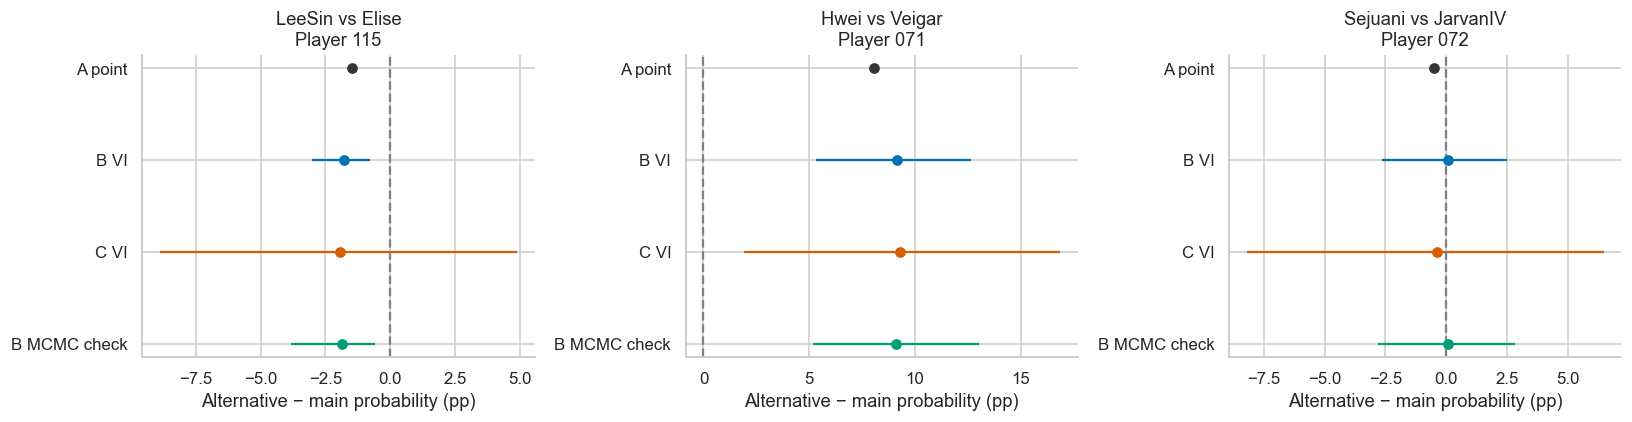

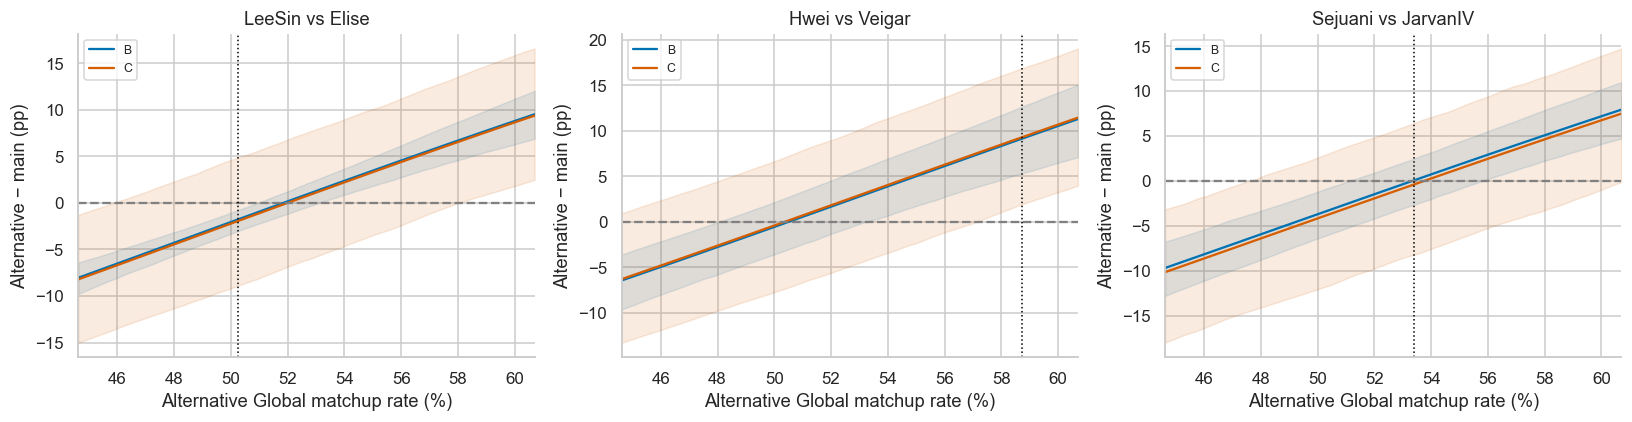

,example,model,main_same_role_games,alternative_same_role_games,supported_low,supported_high,mean_curve_crossing,result,draw_fraction_with_crossing_inside_support,crossing_q025_given_inside_support,crossing_q975_given_inside_support
0,LeeSin vs Elise,B,110,20,0.446,0.607,0.518,crossing,1.000,0.510,0.531
1,LeeSin vs Elise,C,110,20,0.446,0.607,0.520,crossing,0.984,0.465,0.579
2,Hwei vs Veigar,B,61,30,0.446,0.607,0.505,crossing,1.000,0.481,0.533
3,Hwei vs Veigar,C,61,30,0.446,0.607,0.504,crossing,0.957,0.454,0.571
4,Sejuani vs JarvanIV,B,30,21,0.446,0.607,0.533,crossing,1.000,0.511,0.558
5,Sejuani vs JarvanIV,C,30,21,0.446,0.607,0.537,crossing,0.964,0.479,0.593


In [7]:
selected=select_supported_examples(pairs)
rows=[];example_indices=[]
for idx,label,minimum in selected:
    if idx is None:print('No sufficiently supported example:',label);continue
    r=pairs.loc[idx];example_indices.append(idx)
    row={'example':label,'support_tier_both_at_least':minimum,'player':r.player,'lane':r.lane,'opponent':r.opponent,
         'main':r.main_candidate_champion,'alternative':r.alternative_candidate_champion,'signal_pattern':r.signal_pattern}
    for role in ['main','alternative']:
        for col in ['same_role_prior_games','n','all_role_prior_wr','wr','usage','matchup','global_matchup_games','fitting_games','pc_seen']:
            row[role+'_'+col]=r[role+'_'+col]
    for prefix in ['A','B','C']:
        for col in ['main_p','alternative_p','difference_pp']:
            row[prefix+'_'+col]=r[prefix+'_'+col]
        if prefix!='A':
            for col in ['low_pp','high_pp','Pr_alternative_higher']:row[prefix+'_'+col]=r[prefix+'_'+col]
    rows.append(row)
example_table=pd.DataFrame(rows)
# One compact transposed evidence table: each column is a real example, main / alternative in paired cells.
compact={}
for _,r in example_table.iterrows():
    paired=lambda col,fmt:fmt.format(r['main_'+col])+' / '+fmt.format(r['alternative_'+col])
    entry={'Anonymous player':r.player,'Lane / opponent':r.lane+' / '+r.opponent,
        'Main / alternative':r.main+' / '+r.alternative,'Minimum same-role support tier':r.support_tier_both_at_least,
        'Proficiency pattern':r.signal_pattern,'Prior same-role games':paired('same_role_prior_games','{:.0f}'),
        'Prior all-role games':paired('n','{:.0f}'),'Historical raw WR':paired('all_role_prior_wr','{:.1%}'),
        'Historical Beta(1,1) WR':paired('wr','{:.1%}'),'Prior all-role usage':paired('usage','{:.1%}'),
        'Global matchup rates':paired('matchup','{:.1%}'),'Global matchup game counts':paired('global_matchup_games','{:.0f}'),
        'Training player–champion games':paired('fitting_games','{:.0f}'),
        'Training player–champion seen':str(r.main_pc_seen)+' / '+str(r.alternative_pc_seen)}
    for prefix in ['A','B','C']:
        entry[prefix+' main / alternative probability']=f'{r[prefix+"_main_p"]:.1%} / {r[prefix+"_alternative_p"]:.1%}'
        entry[prefix+' alternative − main (pp)']=f'{r[prefix+"_difference_pp"]:+.2f}'
        if prefix!='A':
            entry[prefix+' paired 95% interval (pp)']=f'[{r[prefix+"_low_pp"]:+.2f}, {r[prefix+"_high_pp"]:+.2f}]'
            entry[prefix+' approximate Pr(alternative higher)']=f'{r[prefix+"_Pr_alternative_higher"]:.3f}'
    compact[r.example]=entry
# Strings already carry units, so preserve readable percentages and paired values.
display(pd.DataFrame(compact).style.set_properties(**{'white-space':'normal','max-width':'260px'}))
if len(example_indices):
    fig,axes=plt.subplots(1,len(example_indices),figsize=(5*len(example_indices),4),squeeze=False)
    for ax,idx in zip(axes.flat,example_indices):
        r=pairs.loc[idx]
        for y,prefix,color in [(2,'A','#333333'),(1,'B','#0072B2'),(0,'C','#D55E00')]:
            x=r[prefix+'_difference_pp']
            if prefix=='A':ax.plot(x,y,'o',color=color)
            else:ax.errorbar(x,y,xerr=[[x-r[prefix+'_low_pp']],[r[prefix+'_high_pp']-x]],fmt='o',color=color)
        if len(mcmc_pair_comparison) and idx in mcmc_pair_comparison.pair_index.values:
            check=mcmc_pair_comparison.loc[mcmc_pair_comparison.pair_index.eq(idx)].iloc[0]
            ax.errorbar(check.MCMC_delta_pp,-1,xerr=[[check.MCMC_delta_pp-check.MCMC_low],[check.MCMC_high-check.MCMC_delta_pp]],fmt='o',color='#009E73')
        ax.axvline(0,color='gray',ls='--');ax.set(yticks=[2,1,0,-1],yticklabels=['A point','B VI','C VI','B MCMC check'],xlabel='Alternative − main probability (pp)',
            title=r.main_candidate_champion+' vs '+r.alternative_candidate_champion+'\n'+r.player)
    done()
    mlow,mhigh=train.matchup.quantile([.05,.95]);grid_values=np.linspace(mlow,mhigh,101)
    crossing_rows=[]
    fig,axes=plt.subplots(1,len(example_indices),figsize=(5*len(example_indices),4),squeeze=False)
    for ax,idx in zip(axes.flat,example_indices):
        r=pairs.loc[idx]
        alt=scoring.iloc[[int(r.alternative_row)]]
        grid=pd.concat([alt]*len(grid_values),ignore_index=True);grid['matchup']=grid_values
        for name,model in models.items():
            prefix='B' if model is B else 'C';color='#0072B2' if prefix=='B' else '#D55E00'
            prob=model.predict_draws(grid,draws[name]);main_prob=candidate_draws[name][:,int(r.main_row)]
            delta=100*(prob-main_prob[:,None]);avg=delta.mean(axis=0)
            ax.plot(100*grid_values,avg,color=color,label=prefix)
            ax.fill_between(100*grid_values,np.quantile(delta,.025,axis=0),np.quantile(delta,.975,axis=0),color=color,alpha=.12)
            changes=np.flatnonzero(avg[:-1]*avg[1:]<=0);crossing=np.nan
            if len(changes):
                j=changes[0];a,b=avg[j],avg[j+1]
                crossing=float(grid_values[j]+(-a)*(grid_values[j+1]-grid_values[j])/(b-a)) if b!=a else float(grid_values[j])
            # Draw-specific crossing support diagnoses threshold uncertainty without extrapolating.
            has_draw_crossing=(delta.min(axis=1)<=0)&(delta.max(axis=1)>=0)
            draw_roots=[]
            for curve in delta[has_draw_crossing]:
                positions=np.flatnonzero(curve[:-1]*curve[1:]<=0)
                if len(positions):
                    j=positions[0];a,b=curve[j],curve[j+1]
                    if b!=a:draw_roots.append(float(grid_values[j]+(-a)*(grid_values[j+1]-grid_values[j])/(b-a)))
            root_interval=np.quantile(draw_roots,[.025,.975]) if len(draw_roots) else [np.nan,np.nan]
            crossing_rows.append({'example':r.main_candidate_champion+' vs '+r.alternative_candidate_champion,'model':prefix,
                'main_same_role_games':r.main_same_role_prior_games,'alternative_same_role_games':r.alternative_same_role_prior_games,
                'supported_low':mlow,'supported_high':mhigh,'mean_curve_crossing':crossing,
                'result':'crossing' if np.isfinite(crossing) else 'no crossing within supported range',
                'draw_fraction_with_crossing_inside_support':has_draw_crossing.mean(),
                'crossing_q025_given_inside_support':root_interval[0],'crossing_q975_given_inside_support':root_interval[1]})
        ax.axhline(0,color='gray',ls='--');ax.axvline(100*r.alternative_matchup,color='black',ls=':',linewidth=1)
        ax.set(xlim=(100*mlow,100*mhigh),xlabel='Alternative Global matchup rate (%)',ylabel='Alternative − main (pp)',
             title=r.main_candidate_champion+' vs '+r.alternative_candidate_champion);ax.legend(fontsize=8)
    done();crossings=pd.DataFrame(crossing_rows);table(crossings)
else:crossings=pd.DataFrame();note('No supported examples meet the prespecified categories; no hypothetical cases fabricated.')

## 8. Substantive answer and unresolved uncertainty

Counts and model-conditional conclusions below concern only better-matchup alternatives. Neither observed outcomes nor model estimates verify the outcome of switching to an unplayed champion. The strongest uncertainty assessment is the independent B check when its diagnostics pass; it is not a check of C, external estimates, confounding or draft availability.

In [8]:
opposing=pairs.loc[pairs.signal_pattern.eq('Main more games AND higher WR')]
well=scopes['Both ≥20'];well_opposing=well.loc[well.signal_pattern.eq('Main more games AND higher WR')]
note(f'**Population:** {len(pairs):,} better-matchup pairs from {len(pairs[KEY].drop_duplicates()):,} validation targets and '
     f'{pairs.puuid.nunique()} players. Both champions have ≥20 same-role games in **{len(well):,} pairs**, '
     f'{len(well[KEY].drop_duplicates())} targets and {well.puuid.nunique()} players. '
     f'Genuinely opposing proficiency signals occur in **{len(opposing):,} pairs**; **{len(well_opposing):,}** also meet both-20 support.')
for label,f in [('All better-matchup pairs',pairs),('Opposing proficiency signals',opposing),('Opposing signals AND both ≥20',well_opposing)]:
    if not len(f):note('**'+label+':** no pairs.');continue
    text=[]
    for prefix in ['A','B','C']:
        pref=preference_labels(f,prefix)
        text.append(f'{prefix}: main {np.mean(pref=="Main"):.1%}, alternative {np.mean(pref=="Alternative"):.1%}'+
                    (f', uncertain {np.mean(pref=="Uncertain"):.1%}' if prefix!='A' else ' (point direction only)'))
    note('**'+label+':** '+'; '.join(text)+'. The weighting-specific results above give equal-target and equal-player alternatives.')
all_agree=point_agreement_summary(pairs,'all').iloc[0]
note(f'**Agreement:** all three point directions agree for **{all_agree.pair_weighted:.1%}** of pairs '
     f'(**{all_agree.equal_target:.1%} equal-target; {all_agree.equal_player:.1%} equal-player**). '
     'Agreement about the sign is weaker than evidence that a difference excludes zero. '
     'Adding champion deviations can widen intervals without materially changing mean predictions or validation performance.')
if mcmc_available:
    median_ratio=mcmc_pair_comparison.interval_width_ratio_MCMC_to_VI.median()
    nchanged=(mcmc_pair_comparison.MCMC_interval_class!=mcmc_pair_comparison.VI_interval_class).sum()
    note(f'**Independent B check:** four NUTS chains; diagnostic rule passed: **{mcmc_pass}**. '
         f'Across {len(mcmc_pair_comparison)} reproducibly chosen supported cases, median MCMC/VI interval-width ratio is '
         f'**{median_ratio:.2f}** and **{nchanged}** interval classifications differ. '
         'Do not replace B/C or select an implementation for a preferred result. The check supports or challenges the approximation only within this model and checked cases. '
         'C remains independently unchecked, and its mean-field intervals may still be overconfident.')
    k_check=mcmc_coef_comparison.loc[mcmc_coef_comparison.parameter.eq('k games')].set_index('method')
    amplitude_check=mcmc_coef_comparison.loc[mcmc_coef_comparison.parameter.eq('experience amplitude')].set_index('method')
    note(f'**What the check does not establish:** MCMC k interval is '
         f'**[{k_check.loc["MCMC","low"]:.1f}, {k_check.loc["MCMC","high"]:.1f}] games**, versus '
         f'**[{k_check.loc["VI","low"]:.1f}, {k_check.loc["VI","high"]:.1f}]** under VI. '
         f'The experience-amplitude interval widens from '
         f'**[{amplitude_check.loc["VI","low"]:.2f}, {amplitude_check.loc["VI","high"]:.2f}]** to '
         f'**[{amplitude_check.loc["MCMC","low"]:.2f}, {amplitude_check.loc["MCMC","high"]:.2f}]**. '
         'Agreement on 15 paired classifications does not validate every VI interval or establish a precise learning plateau. '
         'C is independently unchecked; full uncertainty robustness remains incomplete.')
else:note('**Independent uncertainty check incomplete:** standard-framework B MCMC draws were unavailable. VI optimization alone does not validate intervals; B/C uncertainty remains unverified.')
if len(crossings):
    note(f'**Break-even stability:** {crossings.mean_curve_crossing.notna().sum()}/{len(crossings)} model/context mean curves cross inside the documented range. '
         'The table shows whether draw-specific crossings are supported; differing B/C crossings or broad bands weaken a threshold interpretation. '
         'A mean crossing is conditional on all fixed candidate features, not an exact OTP cutoff or a demonstrated switching gain.')
if len(crossings):
    widths=100*(crossings.crossing_q975_given_inside_support-crossings.crossing_q025_given_inside_support)
    c_width=widths.loc[crossings.model.eq('C')].median();b_width=widths.loc[crossings.model.eq('B')].median()
    note(f'**Threshold precision:** median conditional 95% crossing width is **{b_width:.1f} pp** in B '
         f'and **{c_width:.1f} pp** in C. Thus mean break-even points can be descriptively useful, '
         'but precision is model-sensitive and insufficient for an exact actionable cutoff.')
note('**What matters most:** limited champion-specific evidence and model/approximation sensitivity constrain individual tradeoffs. '
     'Same-role support changes the population; it is not a tuned eligibility rule. External matchup rates remain uncertain inputs, '
     'historical WR is an estimate of past outcomes rather than known skill, and draft availability/confounding remain unresolved. '
     'Use “the model favors” or “estimated advantage,” not “switching improves the outcome.” No pair-level independence or recommended-choice win rate is assumed.')
assert all(digest(p)==value for p,value in source_hashes.items())
print('Updated comparison notebook executed; source parquet files and other notebooks unchanged; no test outcomes accessed.')

**Population:** 4,840 better-matchup pairs from 712 validation targets and 117 players. Both champions have ≥20 same-role games in **276 pairs**, 211 targets and 44 players. Genuinely opposing proficiency signals occur in **2,884 pairs**; **138** also meet both-20 support.

**All better-matchup pairs:** A: main 21.0%, alternative 79.0% (point direction only); B: main 35.7%, alternative 25.9%, uncertain 38.4%; C: main 4.2%, alternative 10.3%, uncertain 85.5%. The weighting-specific results above give equal-target and equal-player alternatives.

**Opposing proficiency signals:** A: main 33.2%, alternative 66.8% (point direction only); B: main 41.7%, alternative 20.4%, uncertain 37.9%; C: main 5.7%, alternative 8.9%, uncertain 85.4%. The weighting-specific results above give equal-target and equal-player alternatives.

**Opposing signals AND both ≥20:** A: main 23.2%, alternative 76.8% (point direction only); B: main 2.9%, alternative 61.6%, uncertain 35.5%; C: main 0.0%, alternative 16.7%, uncertain 83.3%. The weighting-specific results above give equal-target and equal-player alternatives.

**Agreement:** all three point directions agree for **62.1%** of pairs (**65.0% equal-target; 67.3% equal-player**). Agreement about the sign is weaker than evidence that a difference excludes zero. Adding champion deviations can widen intervals without materially changing mean predictions or validation performance.

...

**What the check does not establish:** MCMC k interval is **[1.5, 26.6] games**, versus **[2.2, 11.0]** under VI. The experience-amplitude interval widens from **[0.37, 0.51]** to **[0.23, 0.70]**. Agreement on 15 paired classifications does not validate every VI interval or establish a precise learning plateau. C is independently unchecked; full uncertainty robustness remains incomplete.

**Break-even stability:** 6/6 model/context mean curves cross inside the documented range. The table shows whether draw-specific crossings are supported; differing B/C crossings or broad bands weaken a threshold interpretation. A mean crossing is conditional on all fixed candidate features, not an exact OTP cutoff or a demonstrated switching gain.

**Threshold precision:** median conditional 95% crossing width is **4.7 pp** in B and **11.5 pp** in C. Thus mean break-even points can be descriptively useful, but precision is model-sensitive and insufficient for an exact actionable cutoff.

**What matters most:** limited champion-specific evidence and model/approximation sensitivity constrain individual tradeoffs. Same-role support changes the population; it is not a tuned eligibility rule. External matchup rates remain uncertain inputs, historical WR is an estimate of past outcomes rather than known skill, and draft availability/confounding remain unresolved. Use “the model favors” or “estimated advantage,” not “switching improves the outcome.” No pair-level independence or recommended-choice win rate is assumed.

Updated comparison notebook executed; source parquet files and other notebooks unchanged; no test outcomes accessed.
